In [9]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import random, shutil

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.19.1


In [11]:
EXTS = (".jpg", ".jpeg", ".png", ".webp")

# =====================================================================
# <-- SESUAIKAN PATH FOLDER UTAMA DI BAWAH INI -->
# =====================================================================
BASE_PROJECT_DIR = "D:\SEMESTER 5\TATA TULIS ILMIAH\WEEK 12\image_classification_vokal_SIBI"
RAW_SOURCE_DIR   = os.path.join(BASE_PROJECT_DIR, "dataset")
CLASSES          = ['A', 'E', 'I', 'O', 'U']
# =====================================================================

counts = {}
basenames = []
corrupt_files = []

for cls in CLASSES:
    cls_dir = os.path.join(RAW_SOURCE_DIR, cls)
    files = [
        f for f in glob.glob(os.path.join(cls_dir, "*.*"))
        if f.lower().endswith(EXTS)
    ]
    valid_count = 0
    for f in files:
        img = cv2.imread(f)
        if img is None:
            corrupt_files.append(f)
        else:
            valid_count += 1
            basenames.append(os.path.basename(f))
    counts[cls] = valid_count
    print(f"Kelas {cls}: {valid_count} citra valid (total file terbaca: {len(files)})")


total_imgs = sum(counts.values())
print(f"\nTotal citra valid : {total_imgs}")
print(f"File korup/gagal  : {len(corrupt_files)}")
print(f"Nama file unik    : {len(set(basenames))} dari {len(basenames)} file")

if corrupt_files:
    print("Daftar file korup:", corrupt_files[:10])

Kelas A: 493 citra valid (total file terbaca: 493)
Kelas E: 503 citra valid (total file terbaca: 503)
Kelas I: 498 citra valid (total file terbaca: 498)
Kelas O: 497 citra valid (total file terbaca: 497)
Kelas U: 505 citra valid (total file terbaca: 505)

Total citra valid : 2496
File korup/gagal  : 0
Nama file unik    : 2490 dari 2496 file


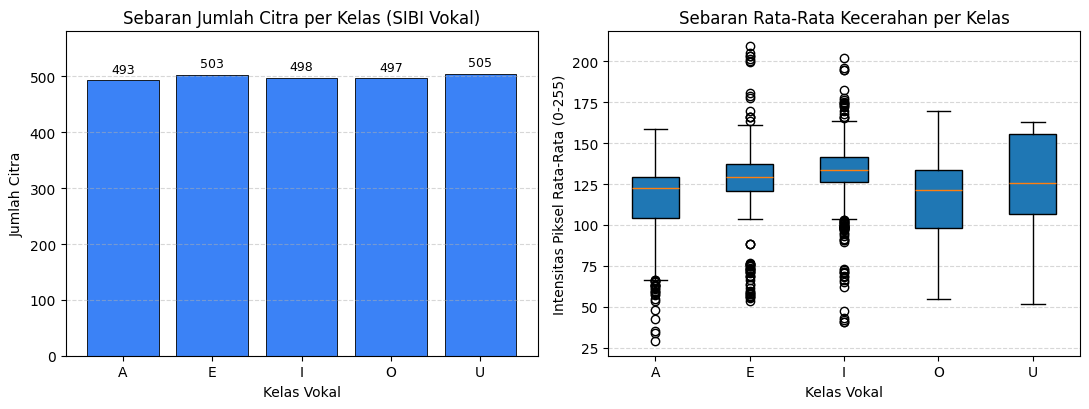

In [12]:
class_counts = []
brightness_by_class = {}

for cls in CLASSES:
    cls_dir = os.path.join(RAW_SOURCE_DIR, cls)
    files = [
        f for f in glob.glob(os.path.join(cls_dir, "*"))
        if os.path.isfile(f) and f.lower().endswith(EXTS)
    ]
    class_counts.append(len(files))

    b_vals = []
    for f in files:
        img = cv2.imread(f)
        if img is not None:
            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
            b_vals.append(float(gray.mean()))
    brightness_by_class[cls] = b_vals

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

bars = axes[0].bar(CLASSES, class_counts, color="#3b82f6", edgecolor="black", linewidth=0.6)
axes[0].set_title("Sebaran Jumlah Citra per Kelas (SIBI Vokal)")
axes[0].set_xlabel("Kelas Vokal")
axes[0].set_ylabel("Jumlah Citra")
axes[0].set_ylim(0, max(class_counts) * 1.15)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
for bar, c in zip(bars, class_counts):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 8,
        str(c),
        ha="center",
        va="bottom",
        fontsize=9,
    )

axes[1].boxplot([brightness_by_class[c] for c in CLASSES], tick_labels=CLASSES, patch_artist=True)
axes[1].set_title("Sebaran Rata-Rata Kecerahan per Kelas")
axes[1].set_xlabel("Kelas Vokal")
axes[1].set_ylabel("Intensitas Piksel Rata-Rata (0-255)")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [14]:
SPLIT_TRAIN_DIR = os.path.join(BASE_PROJECT_DIR, "split", "train")
TEST_DIR        = os.path.join(BASE_PROJECT_DIR, "split", "test")

CLASSES         = ['A', 'E', 'I', 'O', 'U']
TEST_RATIO      = 0.20
EXTS            = (".jpg", ".jpeg", ".png", ".webp", ".bmp")
# =====================================================================

random.seed(SEED)

total_train, total_test = 0, 0

for cls in CLASSES:
    src_cls_dir   = os.path.join(RAW_SOURCE_DIR, cls)
    dst_train_cls = os.path.join(SPLIT_TRAIN_DIR, cls)
    dst_test_cls  = os.path.join(TEST_DIR, cls)

    os.makedirs(dst_train_cls, exist_ok=True)
    os.makedirs(dst_test_cls, exist_ok=True)

    files = [
        f for f in glob.glob(os.path.join(src_cls_dir, "*"))
        if os.path.isfile(f) and f.lower().endswith(EXTS)
    ]
    files.sort()
    random.shuffle(files)

    n_test      = max(1, int(round(len(files) * TEST_RATIO)))
    test_files  = files[:n_test]
    train_files = files[n_test:]

    for idx, f in enumerate(train_files):
        safe_name = f"{cls}_tr_{idx:04d}_{os.path.basename(f)}"
        shutil.copy2(f, os.path.join(dst_train_cls, safe_name))

    for idx, f in enumerate(test_files):
        safe_name = f"{cls}_te_{idx:04d}_{os.path.basename(f)}"
        shutil.copy2(f, os.path.join(dst_test_cls, safe_name))

    total_train += len(train_files)
    total_test  += len(test_files)
    print(f"Kelas {cls}: total={len(files)} -> train={len(train_files)}, test={len(test_files)}")

print(f"\nSelesai! Total train={total_train}, total test={total_test}")

Kelas A: total=493 -> train=394, test=99
Kelas E: total=503 -> train=402, test=101
Kelas I: total=498 -> train=398, test=100
Kelas O: total=497 -> train=398, test=99
Kelas U: total=505 -> train=404, test=101

Selesai! Total train=1996, total test=500


In [16]:
import urllib.request

OUTPUT_DIR = os.path.join(BASE_PROJECT_DIR, "hasil_eksperimen")
os.makedirs(OUTPUT_DIR, exist_ok=True)

model_path = os.path.join(OUTPUT_DIR, "hand_landmarker.task")
model_url = "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task"

if not os.path.exists(model_path):
    print("Mengunduh hand_landmarker.task...")
    urllib.request.urlretrieve(model_url, model_path)
    print("Berhasil diunduh ke:", model_path)
else:
    print("Model sudah ada:", model_path)

base_options = python.BaseOptions(model_asset_path=model_path)
options = vision.HandLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    num_hands=1,
    min_hand_detection_confidence=0.3,
    min_hand_presence_confidence=0.3,
    min_tracking_confidence=0.3,
)
landmarker = vision.HandLandmarker.create_from_options(options)

def extract_hand_landmarks(img_bgr):
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=img_rgb)
    result = landmarker.detect(mp_image)
    if not result.hand_landmarks:
        return None
    hand = result.hand_landmarks[0]
    coords = []
    for lm in hand:
        coords.extend([lm.x, lm.y, lm.z])
    return np.array(coords, dtype=np.float32)  # 21 titik x 3 (x, y, z) = 63 fitur

Mengunduh hand_landmarker.task...
Berhasil diunduh ke: D:\SEMESTER 5\TATA TULIS ILMIAH\WEEK 12\image_classification_vokal_SIBI\hasil_eksperimen\hand_landmarker.task


In [17]:
def extract_split_features(split_root_dir, split_label):
    X_list, y_list = [], []
    failed_samples = []

    for cls in CLASSES:
        cls_dir = os.path.join(split_root_dir, cls)
        files = [
            f for f in glob.glob(os.path.join(cls_dir, "*"))
            if os.path.isfile(f) and f.lower().endswith(EXTS)
        ]
        files.sort()

        ok_count = 0
        for f in files:
            img = cv2.imread(f)
            if img is None:
                failed_samples.append((cls, os.path.basename(f), "gagal_baca"))
                continue
            feats = extract_hand_landmarks(img)
            if feats is None:
                failed_samples.append((cls, os.path.basename(f), "no_hand_detected"))
                continue
            X_list.append(feats)
            y_list.append(cls)
            ok_count += 1

        print(f"[{split_label}] Kelas {cls}: {ok_count}/{len(files)} citra terekstrak")

    X_arr = np.array(X_list, dtype=np.float32)
    y_arr = np.array(y_list)
    print(f"[{split_label}] Total valid: {len(X_arr)} | Gagal/tidak terdeteksi: {len(failed_samples)} | Shape X: {X_arr.shape}\n")
    return X_arr, y_arr, failed_samples

X_train_raw, y_train_raw, fail_train = extract_split_features(SPLIT_TRAIN_DIR, "TRAIN")
X_test_raw, y_test_raw, fail_test = extract_split_features(TEST_DIR, "TEST")

features_cache_path = os.path.join(OUTPUT_DIR, "sibi_landmarks_raw.npz")
np.savez_compressed(
    features_cache_path,
    X_train=X_train_raw,
    y_train=y_train_raw,
    X_test=X_test_raw,
    y_test=y_test_raw,
)
print("Fitur tersimpan di:", features_cache_path)

[TRAIN] Kelas A: 391/394 citra terekstrak
[TRAIN] Kelas E: 401/402 citra terekstrak
[TRAIN] Kelas I: 394/398 citra terekstrak
[TRAIN] Kelas O: 394/398 citra terekstrak
[TRAIN] Kelas U: 404/404 citra terekstrak
[TRAIN] Total valid: 1984 | Gagal/tidak terdeteksi: 12 | Shape X: (1984, 63)

[TEST] Kelas A: 97/99 citra terekstrak
[TEST] Kelas E: 101/101 citra terekstrak
[TEST] Kelas I: 100/100 citra terekstrak
[TEST] Kelas O: 97/99 citra terekstrak
[TEST] Kelas U: 101/101 citra terekstrak
[TEST] Total valid: 496 | Gagal/tidak terdeteksi: 4 | Shape X: (496, 63)

Fitur tersimpan di: D:\SEMESTER 5\TATA TULIS ILMIAH\WEEK 12\image_classification_vokal_SIBI\hasil_eksperimen\sibi_landmarks_raw.npz


In [18]:
from sklearn.utils.class_weight import compute_class_weight

def normalize_landmarks_batch(X):
    # X shape: (N, 63) -> reshape ke (N, 21, 3)
    pts = X.reshape(-1, 21, 3).copy()
    # Translasi: jadikan wrist (indeks 0) sebagai titik asal (0, 0, 0)
    wrist = pts[:, 0:1, :]
    pts = pts - wrist
    # Skala: normalisasi berdasarkan jarak Euclidean maksimum di bidang XY terhadap wrist
    xy_dist = np.linalg.norm(pts[:, :, :2], axis=2)
    scale = np.max(xy_dist, axis=1, keepdims=True)
    scale = np.maximum(scale, 1e-6)
    pts[:, :, :2] = pts[:, :, :2] / scale[:, :, None]
    pts[:, :, 2] = pts[:, :, 2] / scale
    return pts.reshape(-1, 63).astype(np.float32)

le = LabelEncoder()
le.fit(CLASSES)

y_train_enc = le.transform(y_train_raw)
y_test_enc  = le.transform(y_test_raw)

X_train_norm = normalize_landmarks_batch(X_train_raw)
X_test_norm  = normalize_landmarks_batch(X_test_raw)

num_classes = len(CLASSES)
y_train_cat = keras.utils.to_categorical(y_train_enc, num_classes)
y_test_cat  = keras.utils.to_categorical(y_test_enc, num_classes)

cw_vals = compute_class_weight(class_weight="balanced", classes=np.arange(num_classes), y=y_train_enc)
class_weights = {int(k): float(v) for k, v in enumerate(cw_vals)}

model_e0 = keras.Sequential([
    layers.Input(shape=(63,)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation="softmax"),
])

model_e0.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True)
]

history_e0 = model_e0.fit(
    X_train_norm,
    y_train_cat,
    validation_split=0.2,
    epochs=80,
    batch_size=32,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1,
)

test_loss, test_acc = model_e0.evaluate(X_test_norm, y_test_cat, verbose=0)
y_pred_probs = model_e0.predict(X_test_norm, verbose=0)
y_pred_enc = np.argmax(y_pred_probs, axis=1)

print(f"\n[E0 Baseline] Test Accuracy: {test_acc:.4f} | Test Loss: {test_loss:.4f}\n")
print(classification_report(y_test_enc, y_pred_enc, target_names=le.classes_, digits=4))

Epoch 1/80
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.6610 - loss: 1.0125 - val_accuracy: 0.0000e+00 - val_loss: 4.1665
Epoch 2/80
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9364 - loss: 0.3435 - val_accuracy: 0.0000e+00 - val_loss: 4.8980
Epoch 3/80
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9817 - loss: 0.1387 - val_accuracy: 0.0000e+00 - val_loss: 4.6984
Epoch 4/80
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9880 - loss: 0.0812 - val_accuracy: 0.0000e+00 - val_loss: 4.1246
Epoch 5/80
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9924 - loss: 0.0589 - val_accuracy: 0.0000e+00 - val_loss: 3.5435
Epoch 6/80
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9905 - loss: 0.0456 - val_accuracy: 0.0000e+00 - val_loss: 2.9231
Epoch 7/80
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9931 - loss: 0.0353 - val_accuracy: 0.0000e+00 - val_loss: 2.4901
Epoch 8/80
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9931 - loss: 0.0306 - val

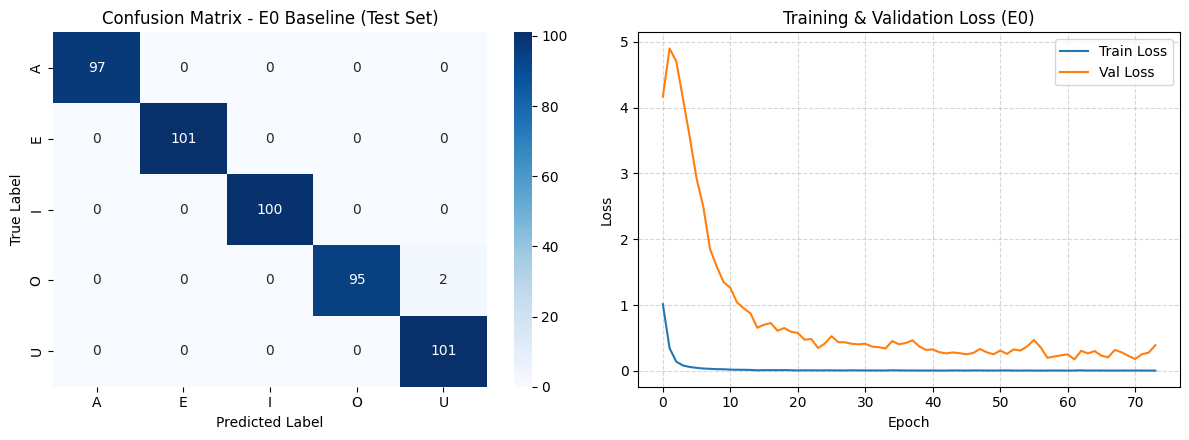

In [19]:
cm = confusion_matrix(y_test_enc, y_pred_enc)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_,
    ax=axes[0],
)
axes[0].set_title("Confusion Matrix - E0 Baseline (Test Set)")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

axes[1].plot(history_e0.history["loss"], label="Train Loss")
axes[1].plot(history_e0.history["val_loss"], label="Val Loss")
axes[1].set_title("Training & Validation Loss (E0)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [20]:
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score

def augment_landmarks_batch(X, y, n_aug_per_sample=2, seed=SEED):
    rng = np.random.default_rng(seed)
    X_aug_list, y_aug_list = [X], [y]

    for _ in range(n_aug_per_sample):
        pts = X.reshape(-1, 21, 3).copy()
        # 1. Skala acak tipis (0.92x - 1.08x) terhadap wrist (indeks 0)
        scales = rng.uniform(0.92, 1.08, size=(pts.shape[0], 1, 1)).astype(np.float32)
        pts = pts * scales
        # 2. Jitter / noise Gaussian halus pada koordinat
        noise = rng.normal(0.0, 0.015, size=pts.shape).astype(np.float32)
        pts = pts + noise
        X_aug_list.append(pts.reshape(-1, 63))
        y_aug_list.append(y.copy())

    X_combined = np.vstack(X_aug_list)
    y_combined = np.concatenate(y_aug_list)
    perm = rng.permutation(len(y_combined))
    return X_combined[perm], y_combined[perm]

# Split stratified train -> sub-train & stratified val agar distribusi kelas di val seimbang
X_tr_sub, X_val_sub, y_tr_sub_enc, y_val_sub_enc = train_test_split(
    X_train_norm,
    y_train_enc,
    test_size=0.2,
    stratify=y_train_enc,
    random_state=SEED,
)

# Terapkan augmentasi hanya pada sub-train (bukan pada val maupun test)
X_tr_aug, y_tr_aug_enc = augment_landmarks_batch(
    X_tr_sub, y_tr_sub_enc, n_aug_per_sample=2, seed=SEED
)

y_tr_aug_cat  = keras.utils.to_categorical(y_tr_aug_enc, num_classes)
y_val_sub_cat = keras.utils.to_categorical(y_val_sub_enc, num_classes)

cw_e1 = compute_class_weight(
    class_weight="balanced", classes=np.arange(num_classes), y=y_tr_aug_enc
)
class_weights_e1 = {int(k): float(v) for k, v in enumerate(cw_e1)}

model_e1 = keras.Sequential([
    layers.Input(shape=(63,)),
    layers.Dense(128, activation=None),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.3),
    layers.Dense(64, activation=None),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation="softmax"),
])

model_e1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks_e1 = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=12, restore_best_weights=True
    )
]

history_e1 = model_e1.fit(
    X_tr_aug,
    y_tr_aug_cat,
    validation_data=(X_val_sub, y_val_sub_cat),
    epochs=80,
    batch_size=32,
    class_weight=class_weights_e1,
    callbacks=callbacks_e1,
    verbose=1,
)

loss_e1, acc_e1 = model_e1.evaluate(X_test_norm, y_test_cat, verbose=0)
probs_e1 = model_e1.predict(X_test_norm, verbose=0)
pred_e1 = np.argmax(probs_e1, axis=1)

# Rekap perbandingan E0 vs E1
e0_macro_f1 = f1_score(y_test_enc, y_pred_enc, average="macro")
e1_macro_f1 = f1_score(y_test_enc, pred_e1, average="macro")
e0_err = int(np.sum(y_pred_enc != y_test_enc))
e1_err = int(np.sum(pred_e1 != y_test_enc))

print("\n=== PERBANDINGAN HEAD-TO-HEAD (TEST SET) ===")
print(f"E0 (Baseline) : Acc={test_acc:.4f} | Loss={test_loss:.4f} | Macro-F1={e0_macro_f1:.4f} | Salah={e0_err}/{len(y_test_enc)}")
print(f"E1 (Aug+BN)   : Acc={acc_e1:.4f} | Loss={loss_e1:.4f} | Macro-F1={e1_macro_f1:.4f} | Salah={e1_err}/{len(y_test_enc)}")
print("\nClassification Report E1:")
print(classification_report(y_test_enc, pred_e1, target_names=le.classes_, digits=4))

# Simpan ringkasan metrik ke OUTPUT_DIR
summary_path = os.path.join(OUTPUT_DIR, "ringkasan_eksperimen_e0_e1.npz")
np.savez(
    summary_path,
    classes=np.array(le.classes_),
    y_test=y_test_enc,
    pred_e0=y_pred_enc,
    pred_e1=pred_e1,
    acc_e0=test_acc,
    loss_e0=test_loss,
    macro_f1_e0=e0_macro_f1,
    acc_e1=acc_e1,
    loss_e1=loss_e1,
    macro_f1_e1=e1_macro_f1,
)
print("Ringkasan tersimpan di:", summary_path)

Epoch 1/80
149/149 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9370 - loss: 0.2776 - val_accuracy: 0.8816 - val_loss: 0.5457
Epoch 2/80
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9977 - loss: 0.0402 - val_accuracy: 0.9950 - val_loss: 0.0794
Epoch 3/80
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9983 - loss: 0.0244 - val_accuracy: 0.9950 - val_loss: 0.0307
Epoch 4/80
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9979 - loss: 0.0193 - val_accuracy: 0.9950 - val_loss: 0.0297
Epoch 5/80
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9985 - loss: 0.0162 - val_accuracy: 0.9950 - val_loss: 0.0274
Epoch 6/80
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9981 - loss: 0.0141 - val_accuracy: 0.9950 - val_loss: 0.0292
Epoch 7/80
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9987 - loss: 0.0119 - val_accuracy: 0.9950 - val_loss: 0.0271
Epoch 8/80
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9985 - loss: 0.0112 - val_accuracy: 0.